In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers,models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report,confusion_matrix

In [2]:
(x_train,y_train),(x_test,y_test) = tf.keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 843s 5us/step


In [3]:
x_train,x_test = x_train/255.0,x_test/255.0

In [4]:
y_train = y_train.flatten()
y_test = y_test.flatten()

In [5]:
cnn_model = models.Sequential()

In [6]:
cnn_model.add(
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(32,32,3))
)
cnn_model.add(layers.BatchNormalization())
cnn_model.add(layers.MaxPooling2D((2,2)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
cnn_model.add(
    layers.Conv2D(64,(3,3),activation='relu')
)
cnn_model.add(layers.BatchNormalization())
cnn_model.add(layers.MaxPooling2D((2,2)))

In [8]:
cnn_model.add(
    layers.Conv2D(128,(3,3),activation='relu')
)
cnn_model.add(layers.BatchNormalization())

In [9]:
cnn_model.add(layers.Flatten())
cnn_model.add(layers.Dense(128,activation='relu'))
cnn_model.add(layers.Dropout(0.5))
cnn_model.add(layers.Dense(10,activation='softmax'))

In [10]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,706 (1.36 MB)

 Trainable params: 357,258 (1.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
history = cnn_model.fit(
    x_train,y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=2
)

Epoch 1/10
625/625 - 50s - 79ms/step - accuracy: 0.4491 - loss: 1.6475 - val_accuracy: 0.5502 - val_loss: 1.2508
Epoch 2/10
625/625 - 52s - 84ms/step - accuracy: 0.5924 - loss: 1.1646 - val_accuracy: 0.5769 - val_loss: 1.1734
Epoch 3/10
625/625 - 51s - 82ms/step - accuracy: 0.6544 - loss: 0.9908 - val_accuracy: 0.6317 - val_loss: 1.0662
Epoch 4/10
625/625 - 56s - 89ms/step - accuracy: 0.6946 - loss: 0.8668 - val_accuracy: 0.6007 - val_loss: 1.1815
Epoch 5/10
625/625 - 71s - 114ms/step - accuracy: 0.7268 - loss: 0.7870 - val_accuracy: 0.6345 - val_loss: 1.1168
Epoch 6/10
625/625 - 46s - 73ms/step - accuracy: 0.7500 - loss: 0.7145 - val_accuracy: 0.7095 - val_loss: 0.8532
Epoch 7/10
625/625 - 43s - 69ms/step - accuracy: 0.7719 - loss: 0.6482 - val_accuracy: 0.6655 - val_loss: 1.0029
Epoch 8/10
625/625 - 82s - 131ms/step - accuracy: 0.7941 - loss: 0.5914 - val_accuracy: 0.7212 - val_loss: 0.8292
Epoch 9/10
625/625 - 43s - 68ms/step - accuracy: 0.8084 - loss: 0.5384 - val_accuracy: 0.6959 

In [13]:
test_lose,test_acc = cnn_model.evaluate(x_test,y_test,verbose=2)

313/313 - 3s - 10ms/step - accuracy: 0.7141 - loss: 0.9658


In [15]:
y_pred_probs = cnn_model.predict(x_test)
y_pred = np.argmax(y_pred_probs,axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


In [16]:
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
print(classification_report(y_test,y_pred,target_names=class_names))

              precision    recall  f1-score   support

    Airplane       0.73      0.78      0.75      1000
  Automobile       0.88      0.75      0.81      1000
        Bird       0.75      0.50      0.60      1000
         Cat       0.50      0.62      0.55      1000
        Deer       0.75      0.62      0.68      1000
         Dog       0.60      0.62      0.61      1000
        Frog       0.87      0.74      0.80      1000
       Horse       0.80      0.73      0.76      1000
        Ship       0.75      0.88      0.81      1000
       Truck       0.66      0.90      0.76      1000

    accuracy                           0.71     10000
   macro avg       0.73      0.71      0.71     10000
weighted avg       0.73      0.71      0.71     10000



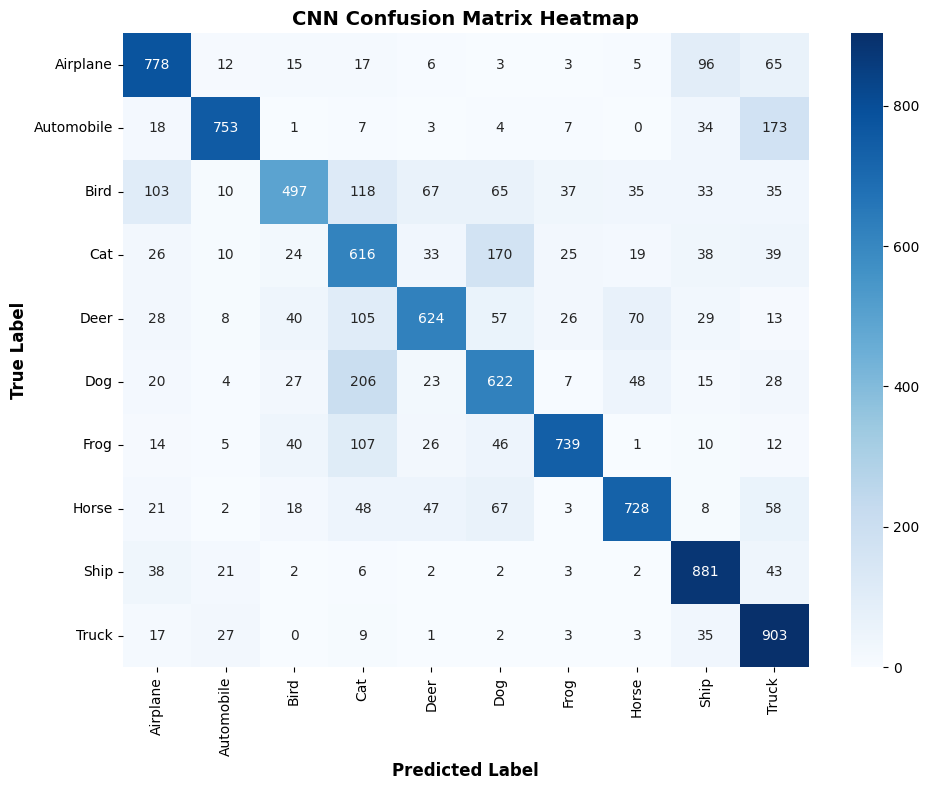

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('CNN Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()